# Boston House Price Prediction

This project aims to predict house prices using machine learning techniques.

The workflow includes:
- Data loading and quality checks
- Exploratory Data Analysis (EDA)
- Correlation analysis
- Feature selection
- Outlier analysis
- Model comparison
- Hyperparameter tuning
- Model evaluation
- MLflow experiment tracking
- Model deployment with Streamlit

## 1. Project Overview

The Boston Housing dataset is used to build a regression model for predicting the median value of houses.

The target variable is `MEDV`, which represents the median house value.

The main objective is not only to build an accurate model, but also to identify a small and meaningful set of input features that can provide good prediction performance.

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import (
    train_test_split,
    ParameterGrid,
    cross_validate
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from xgboost import XGBRegressor

import mlflow
import mlflow.xgboost

In [30]:
df = pd.read_csv("../data/housing.csv", sep=r"\s+", header=None)

In [31]:
columns = [
    "CRIM", "ZN", "INDUS", "CHAS", "NOX", "RM", "AGE",
    "DIS", "RAD", "TAX", "PTRATIO", "B", "LSTAT", "MEDV"
]

df.columns = columns

df.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2


## 2. Data Understanding

In this section, we inspect the structure, columns, data types, and statistical properties of the dataset before performing data cleaning and exploratory analysis.

In [32]:
df.shape

(506, 14)

In [33]:
df.columns


Index(['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX',
       'PTRATIO', 'B', 'LSTAT', 'MEDV'],
      dtype='str')

In [34]:
df.describe()


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,3.613524,11.363636,11.136779,0.069170,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,356.674032,12.653063,22.532806
std,8.601545,23.322453,6.860353,0.253994,0.115878,0.702617,28.148861,2.105710,8.707259,168.537116,2.164946,91.294864,7.141062,9.197104
min,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,0.320000,1.730000,5.000000
25%,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,45.025000,2.100175,4.000000,279.000000,17.400000,375.377500,6.950000,17.025000
50%,0.256510,0.000000,9.690000,0.000000,0.538000,6.208500,77.500000,3.207450,5.000000,330.000000,19.050000,391.440000,11.360000,21.200000
75%,3.677083,12.500000,18.100000,0.000000,0.624000,6.623500,94.075000,5.188425,24.000000,666.000000,20.200000,396.225000,16.955000,25.000000
max,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,396.900000,37.970000,50.000000


In [35]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     506 non-null    float64
 1   ZN       506 non-null    float64
 2   INDUS    506 non-null    float64
 3   CHAS     506 non-null    int64  
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      506 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    int64  
 9   TAX      506 non-null    float64
 10  PTRATIO  506 non-null    float64
 11  B        506 non-null    float64
 12  LSTAT    506 non-null    float64
 13  MEDV     506 non-null    float64
dtypes: float64(12), int64(2)
memory usage: 55.5 KB


In [36]:
df.isnull().sum()

CRIM       0
ZN         0
INDUS      0
CHAS       0
NOX        0
RM         0
AGE        0
DIS        0
RAD        0
TAX        0
PTRATIO    0
B          0
LSTAT      0
MEDV       0
dtype: int64

In [37]:
df.duplicated().sum()

np.int64(0)

## 3. Exploratory Data Analysis (EDA)

In this section, we explore the distributions of the features and the target variable, and examine the relationships between the features and house prices.

The goal is to understand the dataset visually before performing correlation analysis and feature selection.

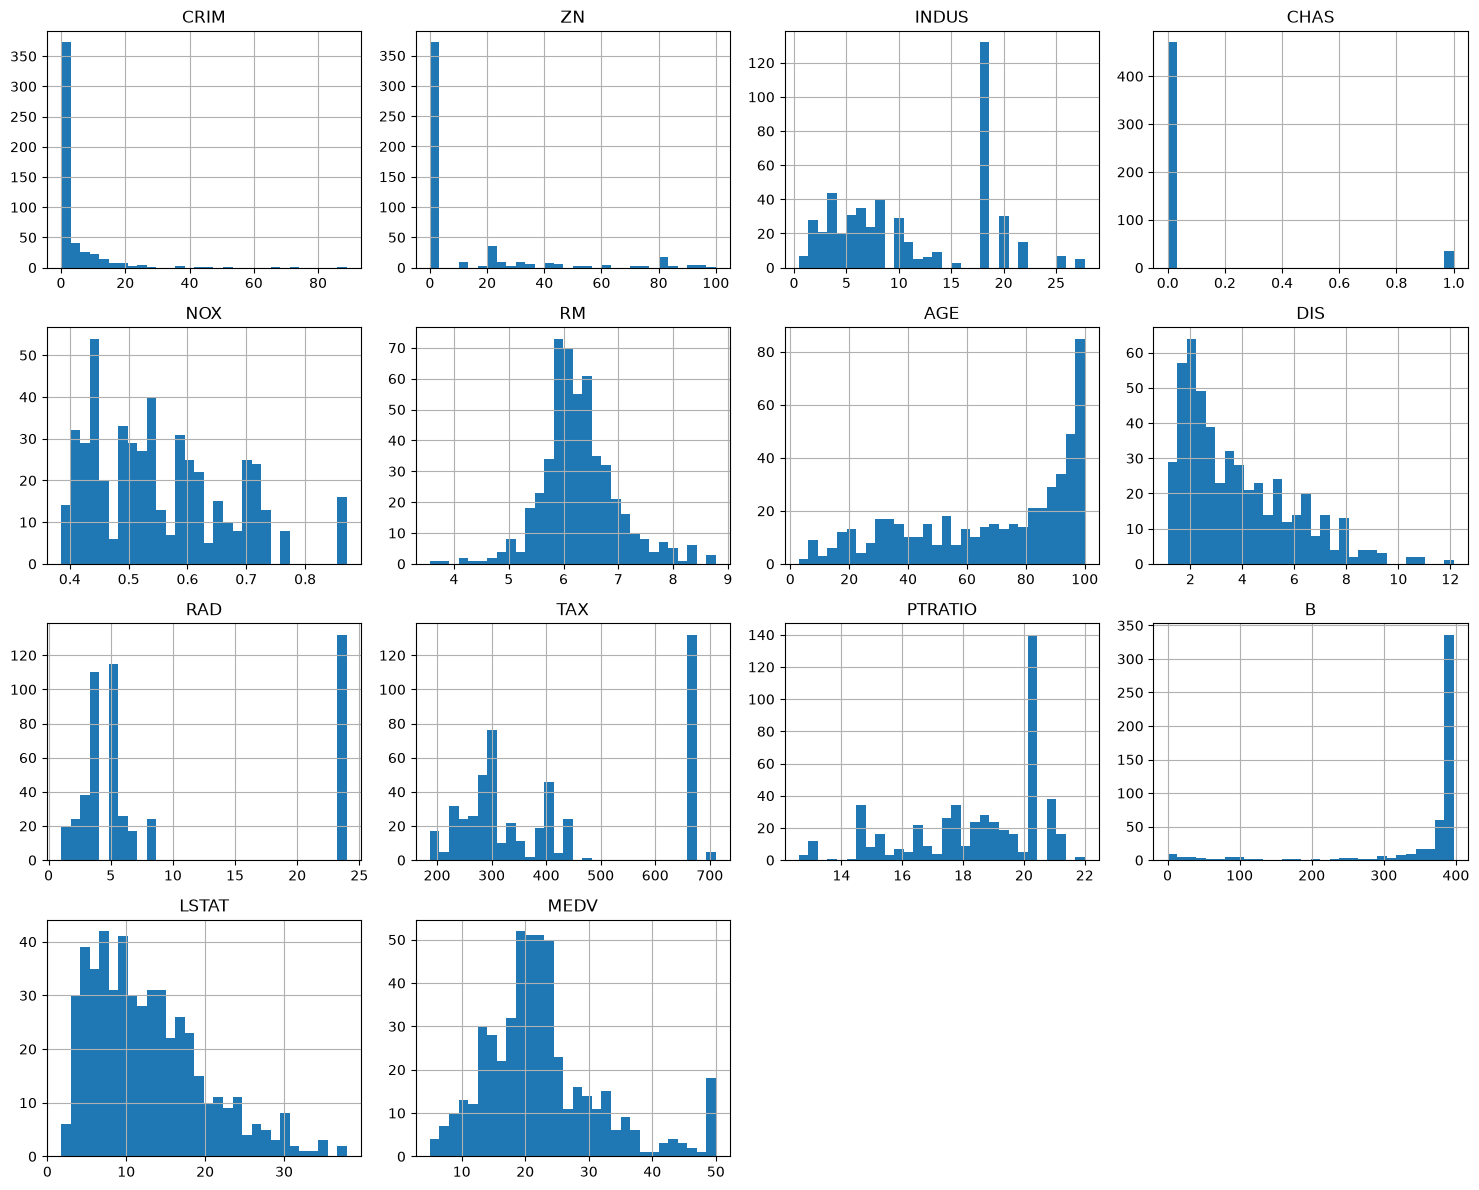

In [38]:
df.hist(figsize=(15, 12), bins=30)
plt.tight_layout()
plt.show()

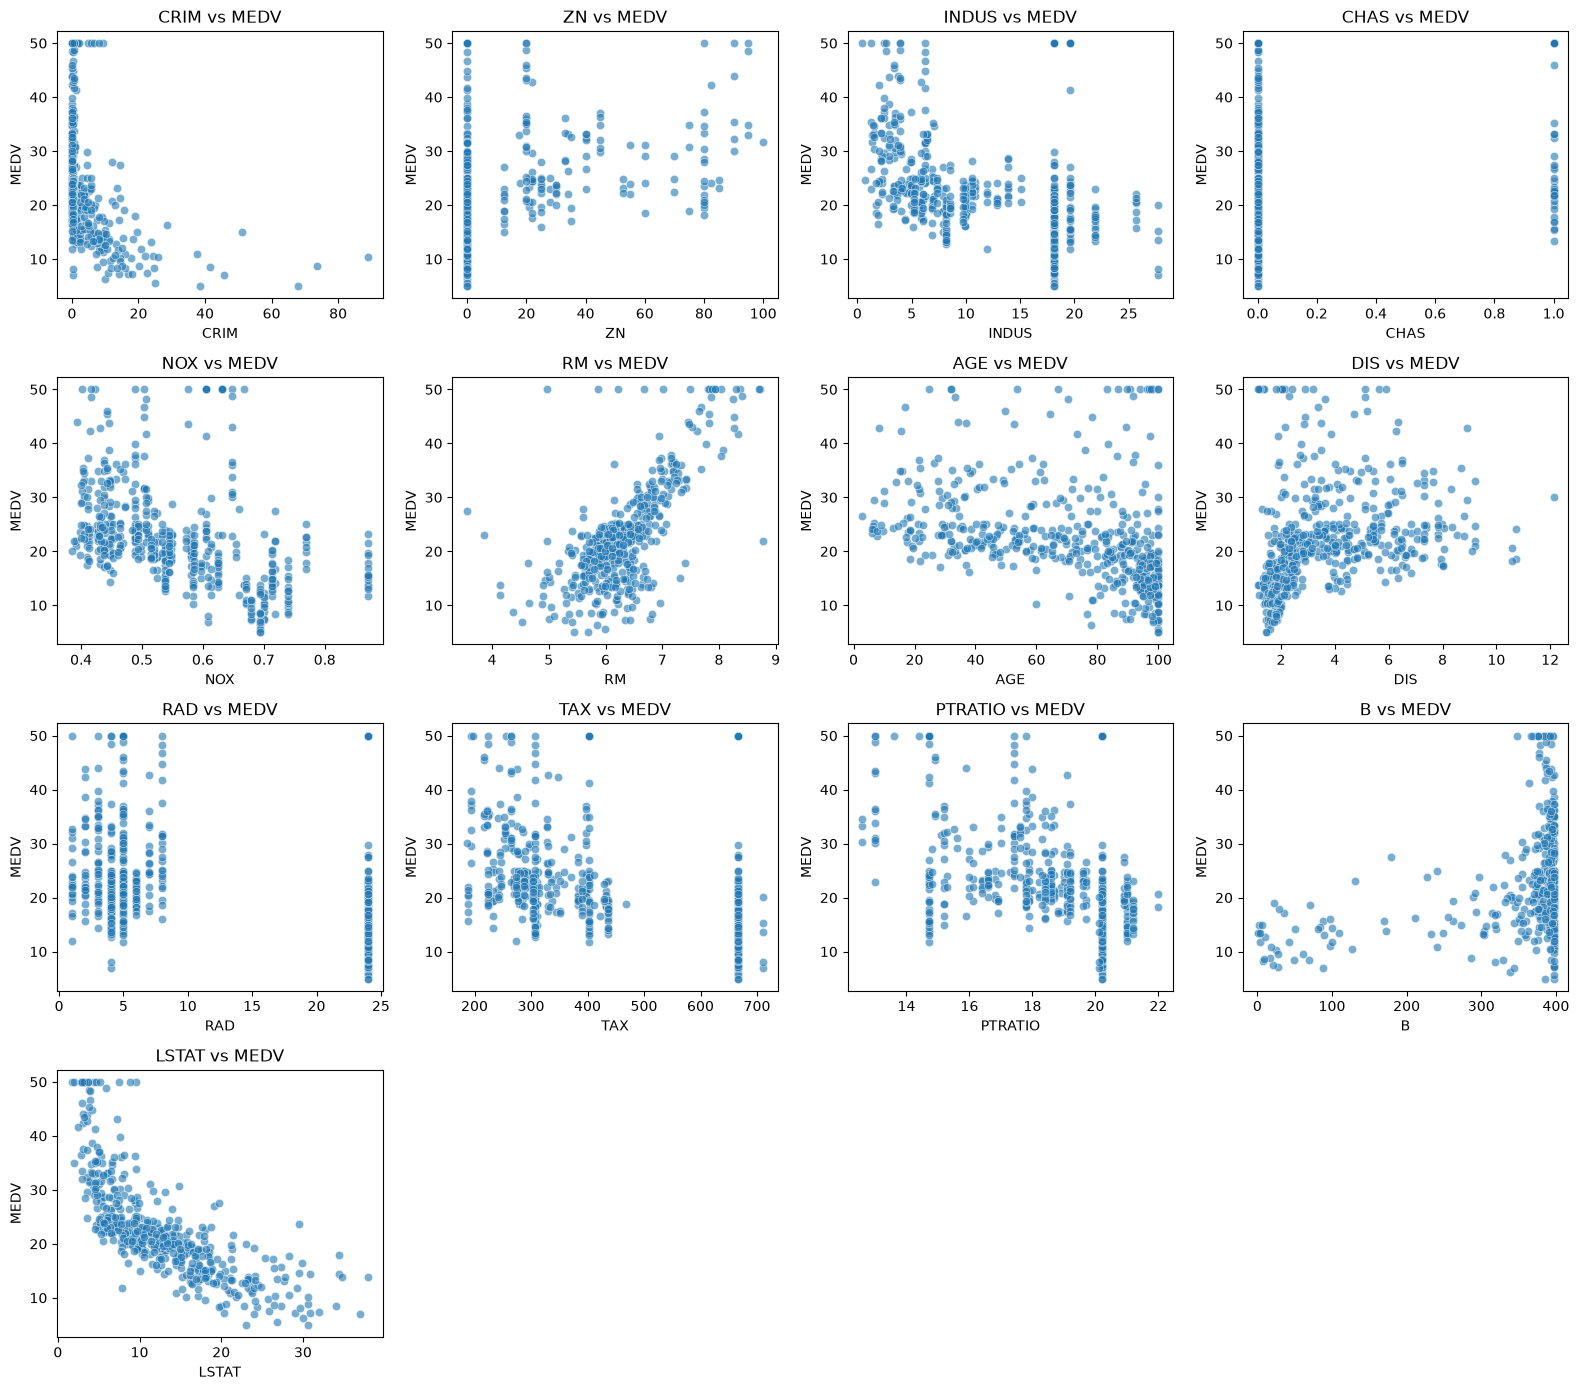

In [39]:
fig, axes = plt.subplots(4, 4, figsize=(16, 14))

features = df.columns[:-1]

for ax, feature in zip(axes.flat, features):
    sns.scatterplot(data=df, x=feature, y="MEDV", ax=ax, alpha=0.6)
    ax.set_title(f"{feature} vs MEDV")

for ax in axes.flat[len(features):]:
    ax.remove()

plt.tight_layout()
plt.show()

In [40]:
correlation_with_target = df.corr(numeric_only=True)["MEDV"].sort_values(ascending=False)

correlation_with_target

MEDV       1.000000
RM         0.695360
ZN         0.360445
B          0.333461
DIS        0.249929
CHAS       0.175260
AGE       -0.376955
RAD       -0.381626
CRIM      -0.388305
NOX       -0.427321
TAX       -0.468536
INDUS     -0.483725
PTRATIO   -0.507787
LSTAT     -0.737663
Name: MEDV, dtype: float64

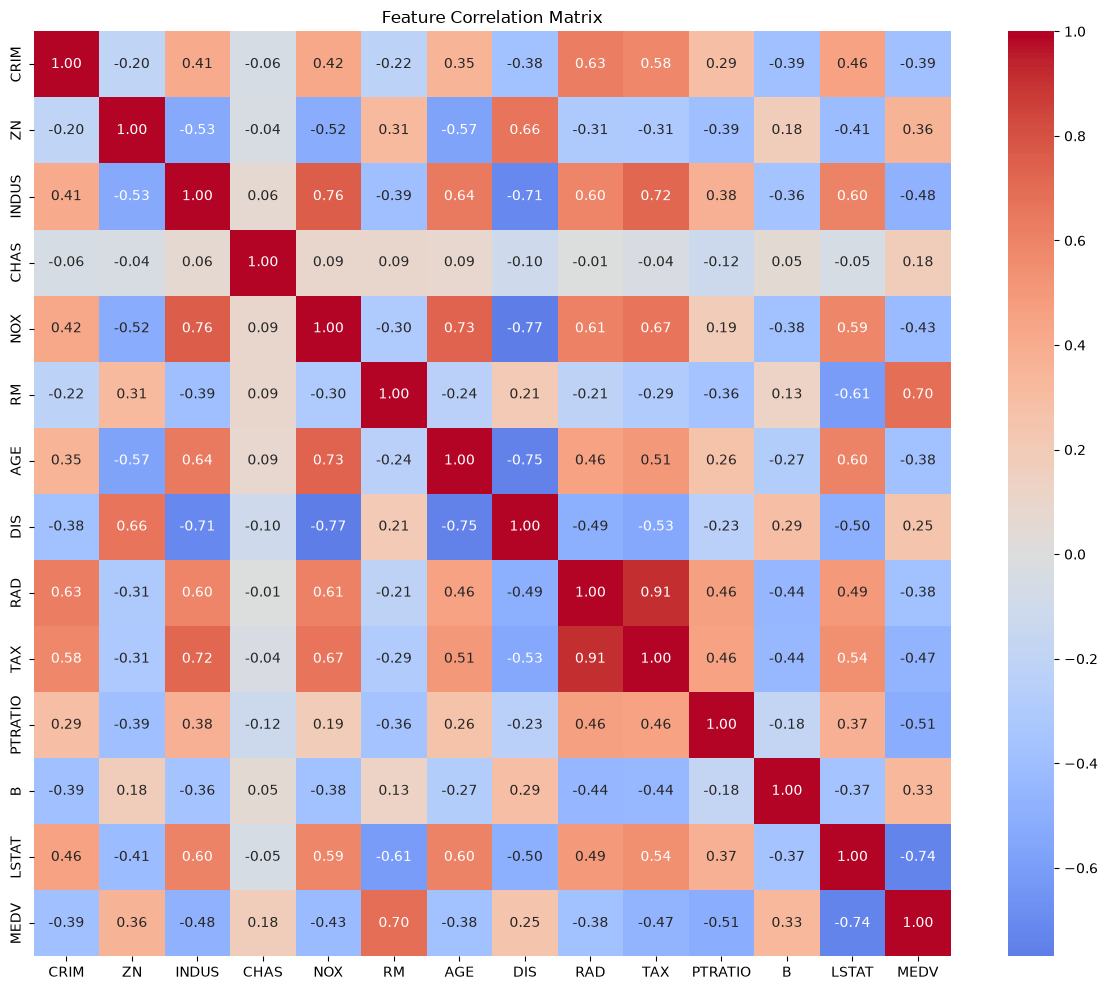

In [41]:
correlation_matrix = df.corr(numeric_only=True)
plt.figure(figsize=(12, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

## 4. Data Preparation

In this section, the selected features and target variable are separated and the dataset is prepared for model training.

In [42]:
X = df.drop(columns=["MEDV"])
y = df["MEDV"]

In [43]:
X.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33


In [44]:
y.head()

0    24.0
1    21.6
2    34.7
3    33.4
4    36.2
Name: MEDV, dtype: float64

## 5. Train-Test Split

The dataset is split into training and testing sets.

The training set is used to build and compare models, while the test set is kept separate for final evaluation.

In [45]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [46]:
X_train.shape, X_test.shape

((404, 13), (102, 13))

In [47]:
y_train.shape, y_test.shape

((404,), (102,))

## 6. Preprocessing and Baseline Models

The dataset is prepared for model training using all available features. Feature scaling is applied only to models that are sensitive to feature magnitude. StandardScaler is used with Linear Regression and SVR, while tree-based models such as Random Forest and XGBoost do not require feature scaling.

Several regression models are then trained using the same training data and all available features. These initial models serve as baseline models and provide a reference point for evaluating model performance before feature selection and hyperparameter tuning.

In [48]:
models = {
    "Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),
    
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),
    
    "SVR": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVR())
    ]),
    
    "XGBoost": XGBRegressor(
        n_estimators=200,
        max_depth=3,
        learning_rate=0.1,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )
}

## 7. Model Evaluation

Model performance is evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R² score.

Lower MAE and RMSE indicate better performance, while a higher R² score indicates better predictive performance.

## 8. MLflow Experiment Tracking

MLflow is used to track the experiments performed during the model development process.

Each baseline model is recorded as a separate MLflow run with its model name, selected features, and evaluation metrics.

In [21]:
project_root = Path.cwd().parent
mlflow_db = project_root / "mlflow.db"

mlflow.set_tracking_uri(
    f"sqlite:///{mlflow_db.as_posix()}"
)

mlflow.set_experiment(
    "Boston House Price Prediction - Clean"
)

print(
    "MLflow Tracking URI:",
    mlflow.get_tracking_uri()
)

print(
    "Experiment:",
    mlflow.get_experiment_by_name(
        "Boston House Price Prediction - Clean"
    ).name
)

2026/09/14 16:40:06 INFO mlflow.tracking.fluent: Experiment with name 'Boston House Price Prediction - Clean' does not exist. Creating a new experiment.


MLflow Tracking URI: sqlite:///C:/Users/hayru/OneDrive/Desktop/boston-house-price-v2/mlflow.db
Experiment: Boston House Price Prediction - Clean


In [22]:
baseline_results = []

# ⚠️ BU HÜCRE 4 YENİ MLFLOW RUN OLUŞTURUR.
# Linear Regression + Random Forest + SVR + XGBoost

for name, model in models.items():

    with mlflow.start_run(
        run_name=f"Baseline - {name}"
    ):

        model.fit(
            X_train,
            y_train
        )

        y_pred = model.predict(
            X_test
        )

        mae = mean_absolute_error(
            y_test,
            y_pred
        )

        rmse = np.sqrt(
            mean_squared_error(
                y_test,
                y_pred
            )
        )

        r2 = r2_score(
            y_test,
            y_pred
        )

        mlflow.log_params({
            "model": name,
            "feature_set": "13_features",
            "n_features": X_train.shape[1]
        })

        if name == "Random Forest":

            mlflow.log_params({
                "n_estimators": model.n_estimators,
                "random_state": model.random_state
            })

        elif name == "XGBoost":

            mlflow.log_params({
                "n_estimators": model.n_estimators,
                "max_depth": model.max_depth,
                "learning_rate": model.learning_rate,
                "objective": model.objective,
                "random_state": model.random_state
            })

        mlflow.log_metrics({
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2
        })

        mlflow.set_tags({
            "stage": "baseline",
            "model_type": name,
            "feature_set": "13_features"
        })

        predictions_df = pd.DataFrame({
            "actual": y_test.values,
            "predicted": y_pred
        })

        predictions_path = "baseline_predictions.csv"

        predictions_df.to_csv(
            predictions_path,
            index=False
        )

        mlflow.log_artifact(
            predictions_path
        )

        if name == "XGBoost":

            mlflow.xgboost.log_model(
                model,
                name="model"
            )

        else:

            mlflow.sklearn.log_model(
                model,
                name="model"
            )

        baseline_results.append({
            "Model": name,
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2
        })

baseline_results_df = pd.DataFrame(
    baseline_results
)

baseline_results_df

,Model,MAE,RMSE,R2
0,Linear Regression,3.189092,4.928602,0.668759
1,Random Forest,2.045603,2.931559,0.882809
2,SVR,2.731716,5.066413,0.649977
3,XGBoost,1.898506,2.557061,0.910838


## 9. Feature Importance

Feature importance is used to understand which features contribute most to the predictions of the strongest baseline models.

Random Forest and XGBoost are analyzed because they achieved the best baseline performance.

The importance values will be used to support the feature selection process.

### 9.1 Random Forest Feature Importance

Random Forest provides feature importance values based on the contribution of each feature across the decision trees.

In [28]:
rf_model = models["Random Forest"]

rf_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

rf_importance = rf_importance.sort_values(
    "Importance",
    ascending=False
)

rf_importance

,Feature,Importance
5,RM,0.492383
12,LSTAT,0.323644
7,DIS,0.055872
0,CRIM,0.038159
10,PTRATIO,0.015865
4,NOX,0.015749
9,TAX,0.015650
6,AGE,0.015285
11,B,0.012704
2,INDUS,0.007159


### 9.2 XGBoost Feature Importance

XGBoost provides feature importance values that indicate the relative contribution of each feature to the model.

In [26]:
xgb_model = models["XGBoost"]

xgb_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": xgb_model.feature_importances_
})

xgb_importance = xgb_importance.sort_values(
    "Importance",
    ascending=False
)

xgb_importance

,Feature,Importance
12,LSTAT,0.476772
5,RM,0.236276
4,NOX,0.065203
10,PTRATIO,0.054057
7,DIS,0.046150
0,CRIM,0.027880
9,TAX,0.023301
3,CHAS,0.020932
8,RAD,0.014803
11,B,0.011846


## 10. Feature Selection

Feature selection is performed based on the feature importance results of Random Forest and XGBoost.

The selected features are chosen as candidate features based on their importance across the strongest baseline models.

The effect of feature selection will be evaluated by comparing model performance before and after reducing the number of features.

In [49]:
selected_features = [
    "RM",
    "LSTAT",
    "DIS",
    "NOX",
    "PTRATIO",
    "CRIM"
]

X_selected = X[selected_features]

In [50]:
X_train_selected = X_train[selected_features]
X_test_selected = X_test[selected_features]

In [51]:
X_train_selected.shape

(404, 6)

In [52]:
X_test_selected.shape

(102, 6)

## 11. Selected Features Model Evaluation

The selected features are evaluated using the same baseline model configurations used previously.

The goal is to compare the performance of models trained with all 13 features against models trained with the selected features.

In [53]:
selected_models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),
    
    "XGBoost": XGBRegressor(
        n_estimators=200,
        max_depth=3,
        learning_rate=0.1,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )
}

In [54]:
selected_results = []

# ⚠️ BU HÜCRE 2 YENİ MLFLOW RUN OLUŞTURUR.
# Random Forest + XGBoost

for name, model in selected_models.items():

    with mlflow.start_run(
        run_name=f"Feature Selected - {name}"
    ):

        model.fit(
            X_train_selected,
            y_train
        )

        y_pred = model.predict(
            X_test_selected
        )

        mae = mean_absolute_error(
            y_test,
            y_pred
        )

        rmse = np.sqrt(
            mean_squared_error(
                y_test,
                y_pred
            )
        )

        r2 = r2_score(
            y_test,
            y_pred
        )

        mlflow.log_params({
            "model": name,
            "feature_set": "selected_6_features",
            "n_features": len(selected_features),
            "features": ", ".join(selected_features)
        })

        if name == "Random Forest":

            mlflow.log_params({
                "n_estimators": model.n_estimators,
                "random_state": model.random_state
            })

        elif name == "XGBoost":

            mlflow.log_params({
                "n_estimators": model.n_estimators,
                "max_depth": model.max_depth,
                "learning_rate": model.learning_rate,
                "objective": model.objective,
                "random_state": model.random_state
            })

        mlflow.log_metrics({
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2
        })

        mlflow.set_tags({
            "stage": "feature_selection",
            "model_type": name,
            "feature_set": "6_features"
        })

        predictions_df = pd.DataFrame({
            "actual": y_test.values,
            "predicted": y_pred
        })

        predictions_path = "feature_selected_predictions.csv"

        predictions_df.to_csv(
            predictions_path,
            index=False
        )

        mlflow.log_artifact(
            predictions_path
        )

        if name == "XGBoost":

            mlflow.xgboost.log_model(
                model,
                name="model"
            )

        else:

            mlflow.sklearn.log_model(
                model,
                name="model"
            )

        selected_results.append({
            "Model": name,
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2
        })

selected_results_df = pd.DataFrame(
    selected_results
)

selected_results_df

,Model,MAE,RMSE,R2
0,Random Forest,2.034255,3.036823,0.874242
1,XGBoost,1.987897,2.759735,0.896144


In [56]:
baseline_tree_results = baseline_results_df[
    baseline_results_df["Model"].isin(
        ["Random Forest", "XGBoost"]
    )
].copy()

baseline_tree_results["Feature Set"] = "13 Features"

selected_results_df["Feature Set"] = "6 Features"

comparison_results = pd.concat(
    [
        baseline_tree_results,
        selected_results_df
    ],
    ignore_index=True
)

comparison_results = comparison_results[
    [
        "Feature Set",
        "Model",
        "MAE",
        "RMSE",
        "R2"
    ]
]

comparison_results.sort_values(
    ["Model", "RMSE"]
)

,Feature Set,Model,MAE,RMSE,R2
0,13 Features,Random Forest,2.045603,2.931559,0.882809
2,6 Features,Random Forest,2.034255,3.036823,0.874242
1,13 Features,XGBoost,1.898506,2.557061,0.910838
3,6 Features,XGBoost,1.987897,2.759735,0.896144


### 11.1 Feature Selection Experiment Tracking

The performance of the selected-feature models is tracked using MLflow.

The selected features, number of features, and evaluation metrics are logged for each model.

## 12. Hyperparameter Tuning

Hyperparameters are settings that control how the XGBoost model is trained.

The goal of hyperparameter tuning is to find a combination of settings that improves the model's performance without unnecessarily increasing model complexity.

In [57]:
xgb_param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [2, 3, 4],
    "learning_rate": [0.03, 0.1, 0.2],
    "subsample": [0.8, 1.0]
}

### 12.1 Tuned Model Evaluation

The tuned XGBoost model is evaluated on the test set.

In [58]:
tuning_results = []

param_combinations = list(
    ParameterGrid(xgb_param_grid)
)

print(
    f"Total hyperparameter combinations: "
    f"{len(param_combinations)}"
)

# ⚠️ BU HÜCRE 54 YENİ MLFLOW RUN OLUŞTURUR.
# Her Run = 1 hyperparameter configuration.
# Her configuration kendi içinde 5-fold CV yapar.
# CV fold'larının her biri ayrı MLflow Run değildir.

for i, params in enumerate(
    param_combinations,
    start=1
):

    with mlflow.start_run(
        run_name=f"Tuning - XGBoost - {i:02d}"
    ):

        model = XGBRegressor(
            objective="reg:squarederror",
            random_state=42,
            n_jobs=-1,
            **params
        )

        cv_results = cross_validate(
            model,
            X_train_selected,
            y_train,
            cv=5,
            scoring={
                "MAE": "neg_mean_absolute_error",
                "RMSE": "neg_root_mean_squared_error",
                "R2": "r2"
            },
            n_jobs=-1
        )

        cv_mae = -cv_results["test_MAE"]
        cv_rmse = -cv_results["test_RMSE"]
        cv_r2 = cv_results["test_R2"]

        mean_cv_mae = cv_mae.mean()
        mean_cv_rmse = cv_rmse.mean()
        mean_cv_r2 = cv_r2.mean()

        mlflow.log_params({
            "model": "XGBoost",
            "feature_set": "6_features",
            "n_features": len(selected_features),
            **params
        })

        mlflow.log_metrics({
            "CV_MAE": mean_cv_mae,
            "CV_RMSE": mean_cv_rmse,
            "CV_R2": mean_cv_r2
        })

        mlflow.set_tags({
            "stage": "hyperparameter_tuning",
            "model_type": "XGBoost",
            "feature_set": "6_features"
        })

        tuning_results.append({
            "Run": i,
            **params,
            "CV_MAE": mean_cv_mae,
            "CV_RMSE": mean_cv_rmse,
            "CV_R2": mean_cv_r2
        })

tuning_results_df = pd.DataFrame(
    tuning_results
)

tuning_results_df.sort_values(
    "CV_RMSE"
).head(10)

Total hyperparameter combinations: 54


,Run,learning_rate,max_depth,n_estimators,subsample,CV_MAE,CV_RMSE,CV_R2
10,11,0.03,3,300,0.8,2.370669,3.539013,0.849614
42,43,0.20,3,100,0.8,2.392159,3.539041,0.850384
44,45,0.20,3,200,0.8,2.404810,3.565071,0.848106
46,47,0.20,3,300,0.8,2.424009,3.577035,0.847176
8,9,0.03,3,200,0.8,2.420524,3.601763,0.844040
16,17,0.03,4,300,0.8,2.373905,3.614219,0.842204
30,31,0.10,4,100,0.8,2.395052,3.639276,0.840595
26,27,0.10,3,200,0.8,2.427709,3.648801,0.839819
14,15,0.03,4,200,0.8,2.404200,3.662843,0.837806
43,44,0.20,3,100,1.0,2.465747,3.665678,0.839629


In [59]:
best_tuning_row = tuning_results_df.loc[
    tuning_results_df["CV_RMSE"].idxmin()
]

best_tuning_params = {
    "n_estimators": int(
        best_tuning_row["n_estimators"]
    ),
    "max_depth": int(
        best_tuning_row["max_depth"]
    ),
    "learning_rate": float(
        best_tuning_row["learning_rate"]
    ),
    "subsample": float(
        best_tuning_row["subsample"]
    )
}

best_tuning_params

{'n_estimators': 300, 'max_depth': 3, 'learning_rate': 0.03, 'subsample': 0.8}

In [60]:
best_cv_rmse = best_tuning_row["CV_RMSE"]

best_cv_rmse

np.float64(3.539013307317437)

In [61]:
best_tuned_model = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1,
    **best_tuning_params
)

best_tuned_model.fit(
    X_train_selected,
    y_train
)

y_pred_tuned = best_tuned_model.predict(
    X_test_selected
)

tuned_mae = mean_absolute_error(
    y_test,
    y_pred_tuned
)

tuned_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_tuned
    )
)

tuned_r2 = r2_score(
    y_test,
    y_pred_tuned
)

tuned_results = pd.DataFrame([{
    "Model": "Tuned XGBoost",
    "MAE": tuned_mae,
    "RMSE": tuned_rmse,
    "R2": tuned_r2
}])

tuned_results

,Model,MAE,RMSE,R2
0,Tuned XGBoost,2.051845,2.971485,0.879595


## 13. Final Model

The baseline XGBoost model with the selected features is chosen as the final model because it provides strong predictive performance with a reduced feature set.

In [62]:
final_model = XGBRegressor(
    n_estimators=200,
    max_depth=3,
    learning_rate=0.1,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

# ⚠️ BU HÜCRE TAM OLARAK 1 YENİ MLFLOW RUN OLUŞTURUR.
# Final model 6 selected feature ile yeniden eğitilir.

with mlflow.start_run(
    run_name="Final XGBoost - 6 Features"
):

    final_model.fit(
        X_train_selected,
        y_train
    )

    y_pred_final = final_model.predict(
        X_test_selected
    )

    final_mae = mean_absolute_error(
        y_test,
        y_pred_final
    )

    final_rmse = np.sqrt(
        mean_squared_error(
            y_test,
            y_pred_final
        )
    )

    final_r2 = r2_score(
        y_test,
        y_pred_final
    )

    mlflow.log_params({
        "model": "XGBoost",
        "feature_set": "6_features",
        "n_features": len(selected_features),
        "features": ", ".join(selected_features),
        "n_estimators": final_model.n_estimators,
        "max_depth": final_model.max_depth,
        "learning_rate": final_model.learning_rate,
        "objective": final_model.objective,
        "random_state": final_model.random_state
    })

    mlflow.log_metrics({
        "MAE": final_mae,
        "RMSE": final_rmse,
        "R2": final_r2
    })

    mlflow.set_tags({
        "stage": "final",
        "model_type": "XGBoost",
        "feature_set": "6_features",
        "selection_reason": "best_test_performance"
    })

    final_predictions_df = pd.DataFrame({
        "actual": y_test.values,
        "predicted": y_pred_final
    })

    final_predictions_path = "final_predictions.csv"

    final_predictions_df.to_csv(
        final_predictions_path,
        index=False
    )

    mlflow.log_artifact(
        final_predictions_path
    )

    mlflow.xgboost.log_model(
        final_model,
        name="final_xgboost_model"
    )

In [63]:
final_results = pd.DataFrame([{
    "Model": "Final XGBoost",
    "MAE": final_mae,
    "RMSE": final_rmse,
    "R2": final_r2
}])

final_results

,Model,MAE,RMSE,R2
0,Final XGBoost,1.987897,2.759735,0.896144


In [64]:
model_summary = pd.concat(
    [
        baseline_results_df.assign(
            Stage="Baseline"
        ),
        selected_results_df.assign(
            Stage="Feature Selection"
        ),
        tuned_results.assign(
            Stage="Tuning"
        ),
        final_results.assign(
            Stage="Final"
        )
    ],
    ignore_index=True
)

model_summary[
    [
        "Stage",
        "Model",
        "MAE",
        "RMSE",
        "R2"
    ]
]

,Stage,Model,MAE,RMSE,R2
0,Baseline,Linear Regression,3.189092,4.928602,0.668759
1,Baseline,Random Forest,2.045603,2.931559,0.882809
2,Baseline,SVR,2.731716,5.066413,0.649977
3,Baseline,XGBoost,1.898506,2.557061,0.910838
4,Feature Selection,Random Forest,2.034255,3.036823,0.874242
5,Feature Selection,XGBoost,1.987897,2.759735,0.896144
6,Tuning,Tuned XGBoost,2.051845,2.971485,0.879595
7,Final,Final XGBoost,1.987897,2.759735,0.896144


### 13.1 MLflow Tracking

The tuned XGBoost model and its parameters and evaluation metrics are tracked using MLflow.

In [65]:
mlflow_runs = mlflow.search_runs(
    experiment_names=[
        "Boston House Price Prediction - Clean"
    ]
)

mlflow_runs[
    [
        "run_id",
        "tags.mlflow.runName",
        "status",
        "metrics.MAE",
        "metrics.RMSE",
        "metrics.R2",
        "metrics.CV_MAE",
        "metrics.CV_RMSE",
        "metrics.CV_R2",
        "start_time"
    ]
].sort_values(
    "start_time",
    ascending=False
)

,run_id,tags.mlflow.runName,status,metrics.MAE,metrics.RMSE,metrics.R2,metrics.CV_MAE,metrics.CV_RMSE,metrics.CV_R2,start_time
0,98d729300d9e4a6688ba3e932adb7c2d,Final XGBoost - 6 Features,FINISHED,1.987897,2.759735,0.896144,NaN,NaN,NaN,2026-09-14 13:51:30.548000+00:00
1,f93d5440b6ad43c6b855109f7b29e77b,Tuning - XGBoost - 54,FINISHED,NaN,NaN,NaN,2.456537,3.805355,0.825056,2026-09-14 13:50:33.471000+00:00
2,702c1bfdcf4e44cfb9397783bdcad2bf,Tuning - XGBoost - 53,FINISHED,NaN,NaN,NaN,2.529952,3.775540,0.828488,2026-09-14 13:50:33.146000+00:00
3,791f639c03294db6bf008852f88b34d8,Tuning - XGBoost - 52,FINISHED,NaN,NaN,NaN,2.449587,3.796436,0.825870,2026-09-14 13:50:32.892000+00:00
4,1c0c0dbf81d34162a767b66a69ca4b82,Tuning - XGBoost - 51,FINISHED,NaN,NaN,NaN,2.521322,3.769105,0.829056,2026-09-14 13:50:32.631000+00:00
...,...,...,...,...,...,...,...,...,...,...
56,02ef1c75fcf34b3b8800276d399724dd,Feature Selected - Random Forest,FINISHED,2.034255,3.036823,0.874242,NaN,NaN,NaN,2026-09-14 13:47:41.758000+00:00
57,972bd606c47b464d9ab997c5a75a95c8,Baseline - XGBoost,FINISHED,1.898506,2.557061,0.910838,NaN,NaN,NaN,2026-09-14 13:42:01.186000+00:00
58,8a2fbcb8b27347f591ee869c252a2b55,Baseline - SVR,FINISHED,2.731716,5.066413,0.649977,NaN,NaN,NaN,2026-09-14 13:41:49.843000+00:00
59,c94fd46536a54315b4d35dab23081eca,Baseline - Random Forest,FINISHED,2.045603,2.931559,0.882809,NaN,NaN,NaN,2026-09-14 13:41:36.729000+00:00
